<a href="https://colab.research.google.com/github/MUQADDASHOAIB24/45_assignments/blob/main/file_T1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!git clone https://github.com/inab/trimal.git
!cd trimal/source && make
!cp trimal/source/trimal /usr/local/bin/
!trimal --version

Cloning into 'trimal'...
remote: Enumerating objects: 17085, done.
remote: Counting objects: 100% (159/159), done.
remote: Compressing objects: 100% (71/71), done.
remote: Total 17085 (delta 110), reused 135 (delta 88), pack-reused 16926 (from 2)
Receiving objects: 100% (17085/17085), 65.28 MiB | 21.57 MiB/s, done.
Resolving deltas: 100% (11734/11734), done.
Updating files: 100% (689/689), done.
g++ -Wall -O2  -c alignment.cpp rwAlignment.cpp autAlignment.cpp
g++ -Wall -O2  -c statisticsGaps.cpp
g++ -Wall -O2  -c utils.cpp
g++ -Wall -O2  -c similarityMatrix.cpp
g++ -Wall -O2  -c statisticsConservation.cpp
g++ -Wall -O2  -c sequencesMatrix.cpp
g++ -Wall -O2  -c compareFiles.cpp
g++ -Wall -O2  -o readal readAl.cpp -lm alignment.o statisticsGaps.o utils.o similarityMatrix.o statisticsConservation.o sequencesMatrix.o compareFiles.o
g++ -Wall -O2  -o trimal main.cpp -lm alignment.o statisticsGaps.o utils.o similarityMatrix.o statisticsConservation.o sequencesMatrix.o compareFiles.o
g++ -Wal

In [3]:
from google.colab import files

uploaded = files.upload()

input_file = list(uploaded.keys())[0]

print("T1 align by muscle", input_file)

Saving T1 align by muscle.fas to T1 align by muscle.fas
T1 align by muscle T1 align by muscle.fas


In [4]:
!pip install biopython -q

from Bio import AlignIO

alignment = AlignIO.read(input_file, "fasta")

print("Number of sequences:", len(alignment))
print("Alignment length:", alignment.get_alignment_length())

Number of sequences: 108
Alignment length: 1694


In [5]:
from Bio import SeqIO

records = list(SeqIO.parse(input_file, "fasta"))

lengths = [(record.id, len(record.seq)) for record in records]

lengths.sort(key=lambda x: x[1], reverse=True)

print("Longest 10 sequences:")
for name, length in lengths[:10]:
    print(name, length)

print("\nShortest 10 sequences:")
for name, length in lengths[-10:]:
    print(name, length)

Longest 10 sequences:
D_melanogaster_NP_511060 1694
D_mauritiana_XP_033169747 1694
D_simulans_XP_016038297 1694
D_sechellia_XP_002036784 1694
D_teissieri_XP_043660527 1694
D_yakuba_XP_002099900 1694
D_santomea_XP_039499239 1694
D_erecta_XP_001978446 1694
D_eugracilis_XP_017064110.1 1694
D_suzukii_XP_016936916 1694

Shortest 10 sequences:
Drosophila_guanche_XP_034128928 1694
Drosophila_subobscura_XP_034666849 1694
Drosophila_madeirensis_BFF94418 1694
Glossina_palpalis_gambiensis_A0A1B0AWF7 1694
Glossina_morsitans_morsitans_A0A1B0G8Z4 1694
Glossina_brevipalpis_A0A1A9WSP8 1694
Glossina_austeni_A0A1A9UFT6 1694
Glossina_pallidipes_A0A1A9ZKP8 1694
Teleopsis_dalmanni_XP_037933221 1694
Drosophila_nepalensis_MIE6892138 1694


In [6]:
from Bio import SeqIO

records = list(SeqIO.parse(input_file, "fasta"))

lengths = []

for record in records:
    sequence = str(record.seq).replace("-", "").replace(".", "")
    lengths.append((record.id, len(sequence)))

lengths.sort(key=lambda x: x[1], reverse=True)

print("Longest 10:")
for name, length in lengths[:10]:
    print(name, length)

print("\nShortest 10:")
for name, length in lengths[-10:]:
    print(name, length)

Longest 10:
D_palustris_KAL7744171 1284
Bactrocera_neohumeralis_XP_050335571 669
Eurosta_solidaginis_XP_067613169 659
Zeugodacus_cucurbitae_XP_028897738 650
Bactrocera_oleae_XP_014094518 648
Bactrocera_latifrons_XP_018803407 647
Bactrocera_dorsalis_XP_011199907 647
Bactrocera_tryoni_XP_039966633 647
Ceratitis_capitata_XP_004530603 638
Rhagoletis_pomonella_XP_036326058 637

Shortest 10:
Hermetia_illucens_XP_037907597 375
D_pseudotakahashii_KAH8354392 334
D_subobscura_XP_034652410 232
D_madeirensis_BFG03949 229
D_guanche_XP_034126534 224
D_obscura_XP_022228315 211
Drosophila_subobscura_XP_034666849 210
Drosophila_madeirensis_BFF94418 210
Drosophila_guanche_XP_034128928 207
D_obscura_XP_022231437 201


In [7]:
from Bio import AlignIO

alignment = AlignIO.read(input_file, "fasta")

total = sum(len(record.seq) for record in alignment)

gaps = sum(
    str(record.seq).count("-") + str(record.seq).count(".")
    for record in alignment
)

print("Total alignment positions:", total)
print("Total gaps:", gaps)
print("Gap percentage:", round((gaps / total) * 100, 2), "%")

Total alignment positions: 182952
Total gaps: 127181
Gap percentage: 69.52 %


In [8]:
import numpy as np

alignment_array = np.array([
    list(str(record.seq))
    for record in alignment
])

occupancy = np.sum(
    (alignment_array != '-') & (alignment_array != '.'),
    axis=0
)

print("Total alignment columns:", len(occupancy))
print("Columns with at least 50% occupancy:", np.sum(occupancy >= 54))
print("Columns with at least 70% occupancy:", np.sum(occupancy >= 76))
print("Columns with at least 90% occupancy:", np.sum(occupancy >= 98))

Total alignment columns: 1694
Columns with at least 50% occupancy: 514
Columns with at least 70% occupancy: 440
Columns with at least 90% occupancy: 269


In [9]:
for record in alignment:
    seq = str(record.seq)

    gap_count = seq.count('-') + seq.count('.')
    gap_percentage = (gap_count / len(seq)) * 100

    print(record.id, round(gap_percentage, 2), "%")

D_melanogaster_NP_511060 67.65 %
D_mauritiana_XP_033169747 67.77 %
D_simulans_XP_016038297 67.77 %
D_sechellia_XP_002036784 67.77 %
D_teissieri_XP_043660527 67.47 %
D_yakuba_XP_002099900 67.36 %
D_santomea_XP_039499239 67.36 %
D_erecta_XP_001978446 67.95 %
D_eugracilis_XP_017064110.1 69.83 %
D_suzukii_XP_016936916 69.01 %
D_elegans_XP_017119474 69.48 %
D_subpulchrella_XP_037723765 68.0 %
D_gunungcola_XP_052856601 69.72 %
D_ficusphila_XP_017054789 69.48 %
D_biarmipes_XP_016948525 69.78 %
D_rhopaloa_XP_016986968 69.01 %
D_takahashii_XP_070075187 69.13 %
D_pseudotakahashii_KAH8354391 68.77 %
D_setifemur_KAH8420489 66.82 %
D_pandora_KAH8313978 67.95 %
D_ananassae_XP_001966613 67.65 %
D_pseudoananassae_KAH8341702 68.0 %
D_bipectinata_XP_017102345 66.23 %
D_pseudoobscura_pseudoobscura_Q9U9I5 68.3 %
D_pseudoobscura_XP_001355250 68.3 %
D_persimilis_XP_002025231 68.3 %
D_miranda_XP_017137782 68.3 %
D_madeirensis_BFG02989 67.95 %
D_obscura_XP_022219118 68.12 %
D_subobscura_XP_034671297 67.83 %
D

In [10]:
for record in records:
    if "D_palustris" in record.id:
        seq = str(record.seq).replace("-", "").replace(".", "")

        print("Sequence:", record.id)
        print("Actual protein length:", len(seq))
        print("First 100 amino acids:", seq[:100])
        print("Last 100 amino acids:", seq[-100:])

Sequence: D_palustris_KAL7744171
Actual protein length: 1284
First 100 amino acids: MSLQDESFPADELFDNLDASTANRSRSLKRQFCLRLELPETEHFQNESPFLNSDCSEETCASDPLGLERDHEEEAKNGSIGNNDGIKSGHDHAQNAQLGS
Last 100 amino acids: ASAYDLLGRLLEINPHDRISAEEALNHPFFTELPEMAPAAPTTPVAMPPRKVATTTTTRRRATKAAAAGGGGGGGGTATAADNQQTMATGEQLHPTLNKL


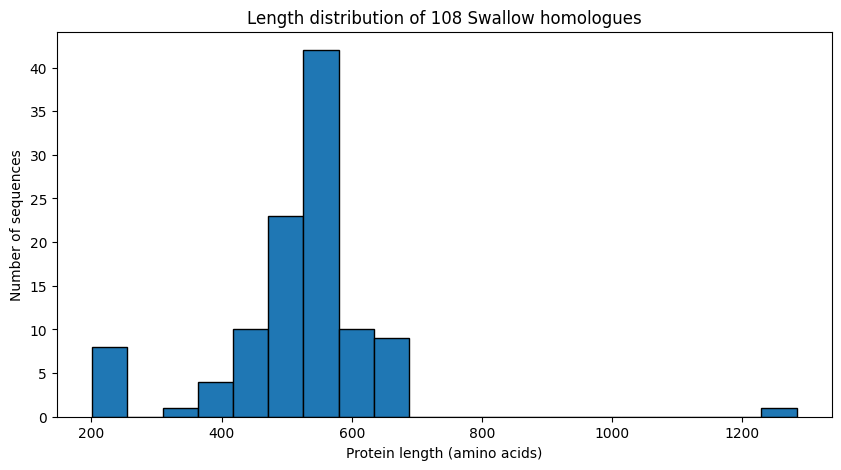

In [11]:
import matplotlib.pyplot as plt

protein_lengths = [
    len(str(record.seq).replace("-", "").replace(".", ""))
    for record in records
]

plt.figure(figsize=(10, 5))
plt.hist(protein_lengths, bins=20, edgecolor="black")
plt.xlabel("Protein length (amino acids)")
plt.ylabel("Number of sequences")
plt.title("Length distribution of 108 Swallow homologues")
plt.show()

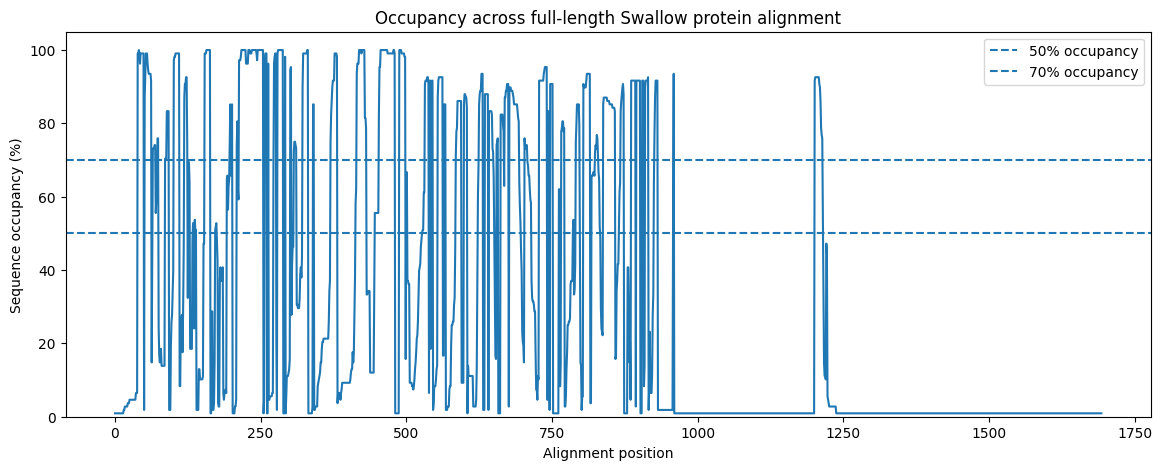

In [12]:
import matplotlib.pyplot as plt
import numpy as np

occupancy_percentage = (occupancy / 108) * 100

plt.figure(figsize=(14, 5))

plt.plot(occupancy_percentage)
plt.axhline(y=50, linestyle='--', label='50% occupancy')
plt.axhline(y=70, linestyle='--', label='70% occupancy')

plt.xlabel("Alignment position")
plt.ylabel("Sequence occupancy (%)")
plt.title("Occupancy across full-length Swallow protein alignment")
plt.legend()
plt.ylim(0, 105)
plt.show()

In [13]:
zero_columns = np.sum(occupancy == 0)

print("Total alignment columns:", len(occupancy))
print("Completely empty columns:", zero_columns)
print("Columns containing amino acids:", np.sum(occupancy > 0))

Total alignment columns: 1694
Completely empty columns: 0
Columns containing amino acids: 1694


In [14]:
for record in alignment:
    seq = str(record.seq)

    # Positions 951 to 1694
    region = seq[950:]

    amino_acids = sum(
        aa not in "-." for aa in region
    )

    if amino_acids > 0:
        print(record.id, amino_acids)

D_melanogaster_NP_511060 18
D_mauritiana_XP_033169747 18
D_simulans_XP_016038297 18
D_sechellia_XP_002036784 18
D_teissieri_XP_043660527 18
D_yakuba_XP_002099900 18
D_santomea_XP_039499239 18
D_erecta_XP_001978446 17
D_eugracilis_XP_017064110.1 18
D_suzukii_XP_016936916 18
D_elegans_XP_017119474 18
D_subpulchrella_XP_037723765 18
D_gunungcola_XP_052856601 18
D_ficusphila_XP_017054789 18
D_biarmipes_XP_016948525 14
D_rhopaloa_XP_016986968 18
D_takahashii_XP_070075187 18
D_pseudotakahashii_KAH8354391 18
D_setifemur_KAH8420489 18
D_pandora_KAH8313978 17
D_ananassae_XP_001966613 17
D_pseudoananassae_KAH8341702 25
D_bipectinata_XP_017102345 39
D_pseudoobscura_pseudoobscura_Q9U9I5 17
D_pseudoobscura_XP_001355250 17
D_persimilis_XP_002025231 17
D_miranda_XP_017137782 17
D_madeirensis_BFG02989 19
D_obscura_XP_022219118 19
D_subobscura_XP_034671297 19
D_guanche_XP_034124869 19
D_ironensis_KAH8308571 17
D_bunnanda_KAH8265935 17
D_tropicalis_XP_068159999 19
D_navojoa_XP_017964878 12
D_mojavensis_

In [15]:
for record in alignment:
    if "D_palustris" in record.id or "D_melanogaster" in record.id:

        seq = str(record.seq)

        occupied = [
            i + 1 for i, aa in enumerate(seq)
            if aa not in "-."
        ]

        print("\nSequence:", record.id)
        print("First occupied position:", min(occupied))
        print("Last occupied position:", max(occupied))
        print("Total amino acids:", len(occupied))


Sequence: D_melanogaster_NP_511060
First occupied position: 40
Last occupied position: 1223
Total amino acids: 548

Sequence: D_palustris_KAL7744171
First occupied position: 40
Last occupied position: 1694
Total amino acids: 1284


In [16]:
for record in alignment:
    if "D_palustris" in record.id:

        extension = str(record.seq)[1223:]
        extension = extension.replace("-", "").replace(".", "")

        print("D. palustris additional C-terminal region")
        print("Length:", len(extension))
        print("Sequence:")
        print(extension)

D. palustris additional C-terminal region
Length: 471
Sequence:
MYMRNLLLALRHVHKFNIIHRDVKPSNFLYNRRQGKFLLVDFGLAQHVTVSQSQPQLPAPVPSAAQQDVRRGNIVIANSKRPRERESLIASQQQQHQAGAGSAAAAAARDTDATLGGAVKRMRLIEETTSGSSWNKMPLKPVNEIAQSTKASVELTPDDPKQAMADAGDSLAQSQVQAEQQPAGSSGSSKYNTSRAAGGNGKCFCFANPSVCLNCLMKKEVHASRAGTPGYRPPEVLLKYADQTTAVDVWAAGVIFLSILSSVYPFFKAPNDFVALAEIVTIFGDRAIRKTALALERMVTISHRSKSLNLRKLCLRFRHRLIFSDAKMIRKYETPDGRCDVCKNCDQYFFNCLCEESDYVTEPLDPYECFPASAYDLLGRLLEINPHDRISAEEALNHPFFTELPEMAPAAPTTPVAMPPRKVATTTTTRRRATKAAAAGGGGGGGGTATAADNQQTMATGEQLHPTLNKL


In [17]:
from Bio.Seq import Seq
from Bio.SeqRecord import SeqRecord
from Bio import SeqIO

for record in alignment:
    if "D_palustris" in record.id:
        sequence = str(record.seq).replace("-", "").replace(".", "")

        first_region = sequence[:548]

        query = SeqRecord(
            Seq(first_region),
            id="D_palustris_first_548aa",
            description="N-terminal region"
        )

        SeqIO.write(
            query,
            "D_palustris_first_548aa.fasta",
            "fasta"
        )

        print("Extracted length:", len(first_region))

Extracted length: 548


In [18]:
from google.colab import files
files.download("D_palustris_first_548aa.fasta")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from Bio import SeqIO
from Bio.Seq import Seq
from Bio.SeqRecord import SeqRecord

for record in records:
    if "D_palustris" in record.id:

        sequence = str(record.seq).replace("-", "").replace(".", "")

        middle = sequence[548:813]

        query = SeqRecord(
            Seq(middle),
            id="D_palustris_middle_region",
            description="Middle 265 aa"
        )

        SeqIO.write(
            query,
            "D_palustris_middle_265aa.fasta",
            "fasta"
        )

        print("Middle region length:", len(middle))


In [19]:
from Bio import SeqIO
from Bio.Seq import Seq
from Bio.SeqRecord import SeqRecord

for record in records:
    if "D_palustris" in record.id:

        sequence = str(record.seq).replace("-", "").replace(".", "")

        middle = sequence[548:813]

        query = SeqRecord(
            Seq(middle),
            id="D_palustris_middle_region",
            description="Middle 265 aa"
        )

        SeqIO.write(
            query,
            "D_palustris_middle_265aa.fasta",
            "fasta"
        )

        print("Middle region length:", len(middle))

Middle region length: 265


In [20]:
from google.colab import files

files.download("D_palustris_middle_265aa.fasta")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
from Bio import SeqIO
from Bio.Seq import Seq
from Bio.SeqRecord import SeqRecord

for record in records:
    if "D_palustris" in record.id:
        continue

    if "D_subpalustris" in record.id:
        sequence = str(record.seq).replace("-", "").replace(".", "")

        first_region = sequence[:173]

        query = SeqRecord(
            Seq(first_region),
            id="D_subpalustris_first_173aa",
            description="N-terminal region"
        )

        SeqIO.write(
            query,
            "D_subpalustris_first_173aa.fasta",
            "fasta"
        )

        print("Extracted length:", len(first_region))

Extracted length: 173


In [22]:
from google.colab import files

files.download("D_subpalustris_first_173aa.fasta")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
from google.colab import files

uploaded = files.upload()

input_file = list(uploaded.keys())[0]

print("all seq update", input_file)

Saving all seq update.aln to all seq update.aln
all seq update all seq update.aln


In [2]:
import os

for file in os.listdir("/content"):
    if file.endswith((".fasta", ".fa", ".fas", ".aln")):
        print(file)

all seq update.aln


In [3]:
input_file = "/content/all seq update.aln"

with open(input_file, "r") as f:
    for i in range(5):
        print(f.readline().rstrip())

CLUSTAL format alignment by MAFFT (v7.511)


D_melanogaster                                     ------------------------------------------------------------
D_mauritiana_XP_033169747                          --------------------------------------------MSLQDESFPTDELFDQ


In [4]:
from Bio import AlignIO

input_file = "/content/all seq update.aln"

alignment = AlignIO.read(input_file, "clustal")

print("Number of sequences:", len(alignment))
print("Alignment length:", alignment.get_alignment_length())
print("Alignment format: CLUSTAL")

ModuleNotFoundError: No module named 'Bio'

In [7]:
!pip install biopython -q

In [8]:
from Bio import AlignIO

input_file = "/content/all seq update.aln"

alignment = AlignIO.read(input_file, "clustal")

print("Number of sequences:", len(alignment))
print("Alignment length:", alignment.get_alignment_length())
print("Format: CLUSTAL")

Number of sequences: 108
Alignment length: 1936
Format: CLUSTAL


In [9]:
!which trimal
!trimal --version

/bin/bash: line 1: trimal: command not found


In [10]:
!git clone https://github.com/inab/trimal.git
!cd trimal/source && make
!cp trimal/source/trimal /usr/local/bin/

Cloning into 'trimal'...
remote: Enumerating objects: 17092, done.
remote: Counting objects: 100% (166/166), done.
remote: Compressing objects: 100% (79/79), done.
remote: Total 17092 (delta 115), reused 138 (delta 87), pack-reused 16926 (from 2)
Receiving objects: 100% (17092/17092), 65.30 MiB | 16.78 MiB/s, done.
Resolving deltas: 100% (11735/11735), done.
Updating files: 100% (689/689), done.
g++ -Wall -O2  -c alignment.cpp rwAlignment.cpp autAlignment.cpp
g++ -Wall -O2  -c statisticsGaps.cpp
g++ -Wall -O2  -c utils.cpp
g++ -Wall -O2  -c similarityMatrix.cpp
g++ -Wall -O2  -c statisticsConservation.cpp
g++ -Wall -O2  -c sequencesMatrix.cpp
g++ -Wall -O2  -c compareFiles.cpp
g++ -Wall -O2  -o readal readAl.cpp -lm alignment.o statisticsGaps.o utils.o similarityMatrix.o statisticsConservation.o sequencesMatrix.o compareFiles.o
g++ -Wall -O2  -o trimal main.cpp -lm alignment.o statisticsGaps.o utils.o similarityMatrix.o statisticsConservation.o sequencesMatrix.o compareFiles.o
g++ -Wal

In [11]:
!cp /content/trimal/source/trimal /usr/local/bin/
!trimal --version


trimAl v1.5.rev1 build[2025-11-25]



In [14]:
!trimal -in "/content/all seq update.aln" -out "/content/Swa_MAFFT_automated1.fasta" -automated1

In [15]:
import os

output_file = "/content/Swa_MAFFT_automated1.fasta"

print("File exists:", os.path.exists(output_file))

if os.path.exists(output_file):
    print("File size:", os.path.getsize(output_file), "bytes")

File exists: True
File size: 10198 bytes


In [16]:
from Bio import AlignIO

trimmed = AlignIO.read(
    "/content/Swa_MAFFT_automated1.fasta",
    "fasta"
)

print("Number of sequences:", len(trimmed))
print("Trimmed alignment length:", trimmed.get_alignment_length())

ValueError: This FASTA file contains comments at the beginning of the file, which are not
allowed by the 'fasta' parser.

To parse this file, you have three options:

(1) Modify your FASTA file to remove such comments at the beginning of the
file.

(2) Use SeqIO.parse with the 'fasta-pearson' format instead of 'fasta'. This
format is consistent with the FASTA format defined by William Pearson's FASTA
aligner software. This format allows for comments before the first sequence;
lines starting with the ';' character anywhere in the file are also regarded
as comment lines and are ignored.

(3) Use the 'fasta-blast' format. This format regards any lines "starting with
'!', '#', or ';' as comment lines. The 'fasta-blast' format may be safer than
the 'fasta-pearson' format, as it explicitly indicates which lines are comments.


In [17]:
from Bio import AlignIO

trimmed = AlignIO.read(
    "/content/Swa_MAFFT_automated1.fasta",
    "fasta-blast"
)

print("Number of sequences:", len(trimmed))
print("Trimmed alignment length:", trimmed.get_alignment_length())

ValueError: Expected FASTA record starting with '>' character.
If this line is a comment, please use '#', '!', or ';' as the first character, or use the 'fasta-pearson' format for parsing.
Got: 'CLUSTAL format alignment by MAFFT (v7.511)
'

In [18]:
from Bio import AlignIO

trimmed = AlignIO.read(
    "/content/Swa_MAFFT_automated1.fasta",
    "clustal"
)

print("Number of sequences:", len(trimmed))
print("Trimmed alignment length:", trimmed.get_alignment_length())

Number of sequences: 108
Trimmed alignment length: 46
